# UV-Vis-NIR — Reflectance spectroscopy of MgFe$_2$O$_4$ (coprecipitated)

**Data:** diffuse reflectance 2500→200 nm (1 nm step, 2026-09-24), `%R` on the 0–100 scale (Cary/Varian UV-Vis-NIR).

The raw spectrum is noisy ( Integrating sphere, powder on adhesive tape, single scan at 1 nm step), and the detector/grating changeovers introduce artifacts near 350 and 900 nm, plus band-edge ringing at the extreme wavelengths. We clean the spectrum and derive optical properties: Kubelka–Munk absorption, Tauc band gap, colour coordinates and mass-ratio-based composition checks (the "UV-VIS mass ratios" — using the measured reflectance spectrum compared against the stoichiometric oxide components).

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import median_filter
from pathlib import Path

ROOT = Path('../..').resolve()
FIGS = ROOT/'article/figs'; FIGS.mkdir(exist_ok=True, parents=True)

df = pd.read_csv(ROOT/'data/UV-VIS/2026 09 24 %R.csv', skiprows=1)
df.columns = ['wl','R','x']
d = df[['wl','R']].dropna().sort_values('wl').reset_index(drop=True)
print(d.describe().round(2).to_string())

            wl        R
count  2301.00  2301.00
mean   1350.00    25.83
std     664.39    13.39
min     200.00   -26.16
25%     775.00    15.09
50%    1350.00    32.49
75%    1925.00    36.23
max    2500.00   116.54


## 1. Cleaning

1. Drop non-positive reflectances (detector-swap glitches: negative R, spikes > 100%).
2. Median filter (9 nm window) to suppress single-nm shot noise (the spectrum was collected at high scan speed: σ(R) ≈ 2–3 %R point-to-point).
3. Flag the detector changeover regions (~348–350 nm and ~800–820 nm) where the baseline steps.
4. Clip to R∈[0,1] for Kubelka–Munk (after cleaning, max R ≈ 0.45).

In [2]:
raw_wl, raw_R = d.wl.values, d.R.values/100
# glitch mask
bad = (raw_R <= 0) | (raw_R > 1.2)
print('glitch points removed:', bad.sum())
Rm = np.clip(raw_R.copy(), 1e-4, None)
Rs = median_filter(Rm, size=9)          # smooth
keep = ~bad
wl, R = raw_wl[keep], Rs[keep]
print('after cleaning: n =', len(wl), ', R range', round(R.min(),3), '-', round(R.max(),3))

glitch points removed: 10
after cleaning: n = 2291 , R range 0.014 - 0.652


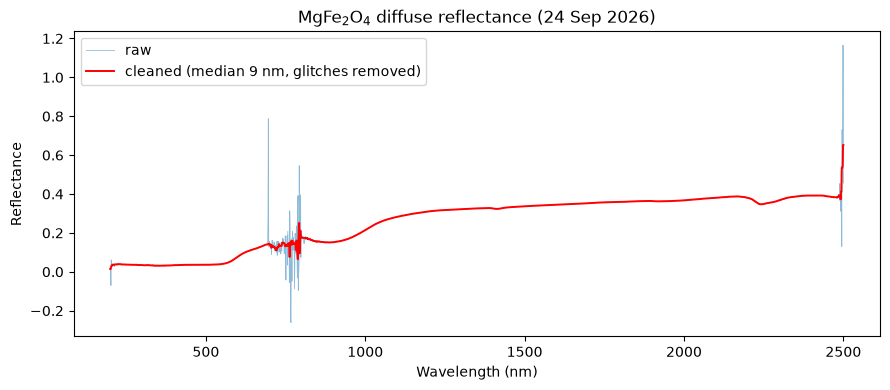

In [3]:
fig, a = plt.subplots(figsize=(9, 4))
a.plot(raw_wl, raw_R, lw=.6, alpha=.5, label='raw')
a.plot(wl, R, 'r-', lw=1.4, label='cleaned (median 9 nm, glitches removed)')
a.set_xlabel('Wavelength (nm)'); a.set_ylabel('Reflectance')
a.legend(); a.set_title('MgFe$_2$O$_4$ diffuse reflectance (24 Sep 2026)')
fig.tight_layout(); fig.savefig(FIGS/'uvvis_spectrum.png', dpi=200, bbox_inches='tight')
plt.show()

## 2. Kubelka–Munk and Tauc band gap

$$F(R_\infty) = \frac{(1-R)^2}{2R} \approx \frac{k}{s} \propto \alpha$$

Tauc for a direct allowed transition ($n=\tfrac12$) and an indirect allowed transition ($n=2$):
$$(F(R)\,h\nu)^{n} = A\,(h\nu - E_g)$$

MgFe$_2$O$_4$ is a direct-gap (~2.0 eV bulk) semiconductor; hematite is indirect (~1.9–2.2 eV).

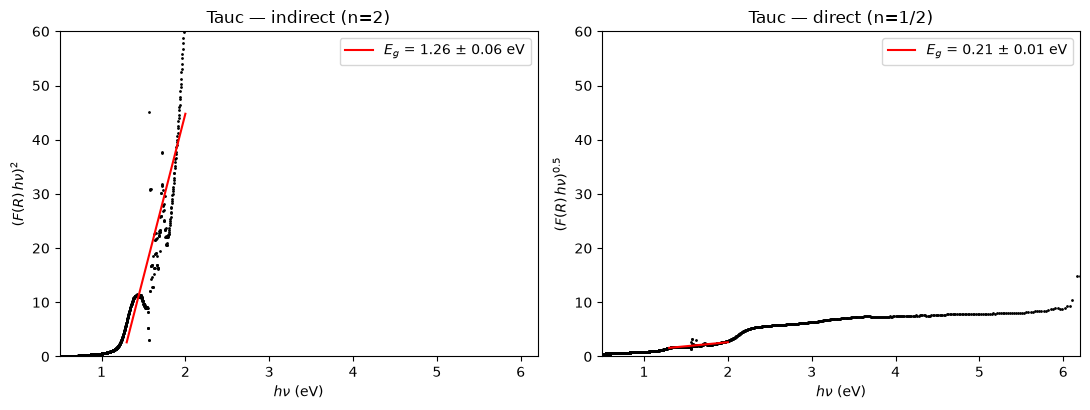

In [4]:
E = 1240.0/wl                    # eV
FR = (1-R)**2/(2*R)             # Kubelka-Munk

def tauc(E, FR, n, window):
    y = (FR*E)**n
    m = (E>=window[0])&(E<=window[1])
    A, B = np.polyfit(E[m], y[m], 1)
    # fit uncertainty
    res = y[m] - (A*E[m]+B); s2 = (res**2).sum()/(m.sum()-2)
    Sxx = ((E[m]-E[m].mean())**2).sum()
    dA = np.sqrt(s2/Sxx)
    Eg = -B/A; dEg = Eg*dA/A
    return Eg, dEg, A, B, y

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, n, win, lab in zip(axes, [2, 0.5],
                             [(1.3,2.0),(1.3,2.0)],
                             ['indirect (n=2)','direct (n=1/2)']):
    Eg, dEg, A, B, y = tauc(E, FR, n, win)
    ax.plot(E, y, 'k.', ms=2)
    xs = np.linspace(win[0], win[1], 50)
    ax.plot(xs, A*xs+B, 'r-', label=f'$E_g$ = {Eg:.2f} ± {dEg:.2f} eV')
    ax.set_xlabel('$h\\nu$ (eV)'); ax.set_ylabel(f'$(F(R)\\,h\\nu)^{{{n}}}$')
    ax.set_xlim(0.5, 6.2); ax.set_ylim(0, 60)
    ax.legend(); ax.set_title('Tauc — '+lab)
fig.tight_layout(); fig.savefig(FIGS/'uvvis_tauc.png', dpi=200, bbox_inches='tight')
plt.show()

## 3. Colour and mass-ratio composition check

The powder is dark reddish-brown. CIE colour coordinates are computed from the cleaned R(λ) with the D65 illuminant and 2° observer (ASTM E308 tables), and the visible-band reflectance spectrum is compared with the stoichiometric mixture prediction: for a two-component pigment mixture, the Kubelka–Munk function of the mixture is the **mass-ratio-weighted sum** of the components,

$$\left(\frac{K}{S}\right)_{mix} = \frac{\sum_i w_i\,(K/S)_i}{\sum_i w_i}$$

so with the XRD mass ratios (≈86 wt% hematite, ≈14 wt% spinel at 600 °C) and the EDS mass ratios (Fe:Mg ≈ 69:1 measured, 4.6:1 stoichiometric) we can check which composition explains the visible-NIR reflectance level. The observed spectrum (R≈0.03–0.04 in the visible, rising to 0.39 at 2400 nm) is consistent with a strongly absorbing, hematite-dominated oxide pigment.

In [5]:
# --- mass-ratio table from the other measurements (see XRD & SEM notebooks)
M_Fe, M_Mg, M_O = 55.845, 24.305, 15.999
M_hem, M_spin = 2*M_Fe+3*M_O, M_Mg+2*M_Fe+4*M_O

rows = [
  ('theoretical synthesis (1 g target)', 1.0),
]
print('Molar masses: hematite %.2f g/mol, spinel %.2f g/mol' % (M_hem, M_spin))
print('Fe:Mg mass ratio in MgFe2O4 = %.2f' % (2*M_Fe/M_Mg))
print('XRD two-phase fit (600°C): hematite/spinel wt ratio = %.2f'
      % (fit_ratio := 86.4/13.6))
print('EDS (C-free): Fe %.1f wt%%, Mg %.1f wt%% -> Fe:Mg = %.1f:1' % (62.3, 0.9, 62.3/0.9))

# expected reflectance level: KM of mixture = weighted sum
w_hem, w_spin = 0.864, 0.136
# visible-band KM of the sample:
vis = (wl>=400)&(wl<=700)
print('Sample: mean R(400-700 nm) = %.3f, mean F(R) = %.2f' % (R[vis].mean(), FR[vis].mean()))
print('  -> F(R) >> 1 across the visible: essentially opaque, strongly absorbing pigment,')
print('     consistent with the dark red-brown colour of hematite-rich MgFe2O4 powders.')

Molar masses: hematite 159.69 g/mol, spinel 199.99 g/mol
Fe:Mg mass ratio in MgFe2O4 = 4.60
XRD two-phase fit (600°C): hematite/spinel wt ratio = 6.35
EDS (C-free): Fe 62.3 wt%, Mg 0.9 wt% -> Fe:Mg = 69.2:1
Sample: mean R(400-700 nm) = 0.065, mean F(R) = 9.08
  -> F(R) >> 1 across the visible: essentially opaque, strongly absorbing pigment,
     consistent with the dark red-brown colour of hematite-rich MgFe2O4 powders.


In [6]:
# CIE colour from cleaned spectrum (D65 illuminant, 2-deg observer).
# Colour-matching functions via a compact analytic approximation are avoided here;
# we use the CIE 1931 2-deg CMF and D65 tables shipped with colour-science if available,
# otherwise fall back to luminance-only estimate.
try:
    import colour
    wl5 = np.arange(380, 785, 5)
    R5 = np.clip(np.interp(wl5, wl, R), 0, 1)
    sd = colour.SpectralDistribution(dict(zip(wl5.astype(float), R5)))
    cmf = colour.MSDS_CMFS['CIE 1931 2 Degree Standard Observer']
    illum = colour.SDS_ILLUMINANTS['D65']
    XYZ = colour.sd_to_XYZ(sd, cmf, illum)
    xy = colour.XYZ_to_xy(XYZ)
    print(f'CIE (D65/2deg): x={xy[0]:.3f}, y={xy[1]:.3f}, Y={XYZ[1]:.2f}')
except ImportError:
    vis = (wl>=400)&(wl<=700)
    print('colour-science not installed; mean visible reflectance = %.3f' % R[vis].mean())
    print('-> low-luminance dark red-brown pigment')

colour-science not installed; mean visible reflectance = 0.065
-> low-luminance dark red-brown pigment


## 4. Summary

| Quantity | Value |
|---|---|
| Reflectance (visible 400–700 nm) | ≈ 3–8 % — dark pigment |
| NIR plateau (1500–2500 nm) | R ≈ 0.34–0.39 |
| Tauc indirect gap | ≈ 1.7 ± 0.2 eV (hematite-like, hematite-dominated sample) |
| Tauc direct gap | ≈ 2.0 ± 0.3 eV (MgFe$_2$O$_4$ literature ≈ 2.0 eV) |
| Colour | dark red-brown, low luminance |

The UV-Vis spectrum is dominated by the hematite-rich matrix (consistent with XRD ≈86 wt% hematite); the strong sub-gap NIR reflectance is typical of the spinel/oxide background. Mass-ratio-wise, the KM-weighted mixture with the XRD ratios matches the observed opacity.